# E2 - Additivity of the Per-Block Distortion Model (DeiT-Small)

E1 fit per-block sensitivities `S_l` in `D ≈ Σ_l S_l·ε_l` by perturbing ONE
block at a time. E2 tests the ADDITIVE part: perturb SETS of blocks
simultaneously and check that measured distortion equals the sum of
single-block contributions -- the load-bearing assumption of a downstream
joint bit-width/token optimizer.

Runs top-to-bottom on a single Colab GPU. Requires E1's
`results/E1/*summary*.json` + `*raw*.csv` (local repo path, else Drive
mount, else manual upload). Does NOT modify the E1 notebook; E1's
already-verified machinery is copied verbatim into clearly marked cells.

**Outputs** (under `results/E2/`): `E2_raw.csv`, `E2_summary.json`,
`additivity_scatter.png`, `interaction_bars.png`, `curvature_plot.png`.

Reviewer-release note: this notebook has no manual-review STOP
checkpoints to convert -- see `E5_allocator_G1.py`'s Section 21/25d and
its `TANDEM_INTERACTIVE` flag for the one file in E1-E5 that does.

## 0. Clone the repo (so this and later notebooks share `results/` via git)

This repo is public -- cloning it needs no authentication.

Clones (or pulls, if already cloned this session) to `/content/tandem`,
then changes into `/content/tandem/notebooks` -- every relative path in
this notebook (`results/E2/...`, and `load_e1_constants()`'s own
`results/E1/` lookup below) resolves exactly as it always has, no
changes needed elsewhere. E1's results, if already pushed, come along
automatically with this same clone -- no Drive mount or manual upload
needed.

In [ ]:
import os

REPO_URL = "https://github.com/fawadsarim/tandem.git"
REPO_DIR = "/content/tandem"

if not os.path.exists(REPO_DIR):
    get_ipython().system(f'git clone -q {REPO_URL} {REPO_DIR}')  # noqa: F821
else:
    print(f"{REPO_DIR} already exists -- pulling latest instead of re-cloning.")
    get_ipython().system(f'git -C {REPO_DIR} pull -q')  # noqa: F821

get_ipython().run_line_magic('cd', f'{REPO_DIR}/experiments/phase1_E1-E5_E4a')  # noqa: F821

## 1. Setup

Installs, imports, global seed, base `CONFIG`, environment capture.
`HF_TOKEN` comes ONLY from Colab Secrets or an env var -- never hardcoded,
no manual-paste line, since this file may be shared/committed.

In [23]:
!pip install -q torch timm datasets matplotlib pandas tqdm scipy

In [ ]:
import hashlib
import itertools
import json
import math
import os
import platform
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

CONFIG = {
    "N_IMAGES": 5000,
    "BATCH_SIZE": 128,
    "SEEDS": [0, 1, 2],
    "MODEL": "deit_small_patch16_224",
}

# Independent verification: results/E2/E2_raw.csv ships committed in this
# repo, so a default Run All resumes from it instantly rather than
# recomputing -- that's a self-consistency check (the checked-in numbers
# still match what this exact code produces), not a substitute for a real
# from-scratch run. Set FORCE_FRESH_RUN = True to ignore any existing
# checkpoint and recompute every row.
FORCE_FRESH_RUN = False

DEVICE = "cuda"
assert torch.cuda.is_available(), (
    "E2 requires a CUDA GPU. In Colab: Runtime > Change runtime type > T4 GPU."
)

RESULTS_DIR = Path("results/E2")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# HF_TOKEN: Colab secrets > env var. Never hardcoded -- this notebook may be
# committed or shared, unlike a scratch session.
try:
    from google.colab import userdata

    try:
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception as e:
        HF_TOKEN = None
        print(f"Colab secret 'HF_TOKEN' not usable ({type(e).__name__}: {e}).")
except ImportError:
    HF_TOKEN = os.environ.get("HF_TOKEN")
print(f"HF_TOKEN detected: {'yes' if HF_TOKEN else 'no'}")

ENVIRONMENT = {
    "torch_version": torch.__version__,
    "timm_version": timm.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_name": torch.cuda.get_device_name(0),
    "platform": platform.platform(),
    "python_version": platform.python_version(),
}
print(json.dumps(ENVIRONMENT, indent=2))

Colab secret 'HF_TOKEN' not usable (TimeoutException: Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.).
HF_TOKEN detected: no
{
  "torch_version": "2.10.0+cu128",
  "timm_version": "1.0.26",
  "cuda_version": "12.8",
  "gpu_name": "Tesla T4",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.35",
  "python_version": "3.12.13"
}


## 2. [VERBATIM FROM E1 - do not modify] ImageNet-1k data loader

ImageNet-1k streaming via HF_TOKEN, no fallback (consolidated away now
that ImageNet-1k access is reliable -- see E1's own Section 2 note).
Identical to E1 so E2's constants stay on the same distribution E1's
were measured on (checked explicitly in Gate (a) below).

In [29]:
from datasets import load_dataset
from torchvision import transforms

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

PREPROCESS = transforms.Compose(
    [
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.PILToTensor(),  # uint8, [3,224,224]
    ]
)


def _to_uint8_chw(pil_img):
    return PREPROCESS(pil_img.convert("RGB"))


def _materialize(example_iter, n, label_key=None):
    """Decode/resize/crop up to n HF-style dict examples into a uint8 tensor + optional labels."""
    imgs = torch.empty((n, 3, 224, 224), dtype=torch.uint8)
    labels = torch.empty(n, dtype=torch.long) if label_key else None
    count = 0
    for ex in tqdm(example_iter, total=n, desc="decoding images"):
        if count >= n:
            break
        imgs[count] = _to_uint8_chw(ex["image"])
        if label_key:
            labels[count] = int(ex[label_key])
        count += 1
    assert count == n, f"expected {n} images, only found {count}"
    return imgs, labels


def load_eval_images(cfg, hf_token):
    """Returns (images_u8, labels, labels_available=True, source="imagenet-1k", n_used).
    No fallback -- fails loudly if ImageNet-1k access isn't actually working."""
    n_requested = cfg["N_IMAGES"]
    assert hf_token, "HF_TOKEN required -- ImageNet-1k access is no longer optional."

    ds = load_dataset("ILSVRC/imagenet-1k", split="validation", streaming=True, token=hf_token)
    probe = next(iter(ds))  # verify access is actually granted before committing
    assert "image" in probe and "label" in probe
    imgs, labels = _materialize(iter(ds), n_requested, label_key="label")
    print(f"{'=' * 70}\nDATA SOURCE: ImageNet-1k (validation, streaming, {n_requested} images)\n{'=' * 70}")
    return imgs, labels, True, "imagenet-1k", n_requested

In [30]:
images_u8, labels, LABELS_AVAILABLE, DATA_SOURCE, N_USED = load_eval_images(CONFIG, HF_TOKEN)
assert images_u8.shape == (N_USED, 3, 224, 224)
assert images_u8.dtype == torch.uint8
if labels is not None:
    assert labels.shape == (N_USED,)

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/294 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/28 [00:00<?, ?it/s]

decoding images:   0%|          | 0/5000 [00:00<?, ?it/s]

DATA SOURCE: ImageNet-1k (validation, streaming, 5000 images)


## 3. [VERBATIM FROM E1 - do not modify] Batch & forward-pass helpers

In [31]:
MEAN_T = torch.tensor(IMAGENET_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_T = torch.tensor(IMAGENET_STD, device=DEVICE).view(1, 3, 1, 1)


def normalize_batch(batch_u8, device=DEVICE):
    x = batch_u8.to(device, non_blocking=True).float() / 255.0
    return (x - MEAN_T) / STD_T


def iterate_batches(images, batch_size):
    n = images.shape[0]
    for start in range(0, n, batch_size):
        yield start, images[start : start + batch_size]


def n_batches_for(n_images, batch_size):
    return math.ceil(n_images / batch_size)


def forward_logits(model, batch_u8, device=DEVICE):
    """Single standardized forward pass: fp16 autocast, fp32 output."""
    x = normalize_batch(batch_u8, device)
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = model(x)
    return logits.float()

## 4. [VERBATIM FROM E1 - do not modify] Model loader

In [32]:
def load_model(cfg):
    try:
        model = timm.create_model(cfg["MODEL"], pretrained=True)
    except Exception:
        tagged = f"{cfg['MODEL']}.fb_in1k"
        print(f"'{cfg['MODEL']}' has no default pretrained tag; retrying as '{tagged}'.")
        model = timm.create_model(tagged, pretrained=True)
    model = model.eval().to(DEVICE).requires_grad_(False)
    assert len(model.blocks) == 12, f"expected 12 transformer blocks, found {len(model.blocks)}"
    return model


model = load_model(CONFIG)
N_BLOCKS = len(model.blocks)
n_params = sum(p.numel() for p in model.parameters())
print(f"Loaded {CONFIG['MODEL']}: {n_params / 1e6:.1f}M params, {N_BLOCKS} blocks, "
      f"{model.num_classes} classes.")

Loaded deit_small_patch16_224: 22.1M params, 12 blocks, 1000 classes.


## 5. [VERBATIM FROM E1 - do not modify] Stats pass - `m_l`

Recomputed fresh in THIS session so Gate (b) can check it against E1's
stored `m_l` -- a divergence would mean the two runs saw different data.

In [33]:
def compute_m_l(model, images, batch_size):
    n_blocks = len(model.blocks)
    sums = [0.0] * n_blocks
    n_total = images.shape[0]

    def make_hook(idx):
        def hook(module, inp, out):
            sums[idx] += out.float().pow(2).mean(dim=tuple(range(1, out.dim()))).sum().item()

        return hook

    handles = [model.blocks[i].register_forward_hook(make_hook(i)) for i in range(n_blocks)]
    try:
        for _, batch in tqdm(
            iterate_batches(images, batch_size),
            total=n_batches_for(images.shape[0], batch_size),
            desc="stats pass",
        ):
            forward_logits(model, batch)
    finally:
        for h in handles:
            h.remove()
    return [s / n_total for s in sums]


m_l = compute_m_l(model, images_u8, CONFIG["BATCH_SIZE"])
for i, m in enumerate(m_l):
    print(f"block {i + 1:2d}: m_l = {m:.6f}")

stats pass:   0%|          | 0/40 [00:00<?, ?it/s]

block  1: m_l = 1.021137
block  2: m_l = 0.579027
block  3: m_l = 0.545971
block  4: m_l = 0.618714
block  5: m_l = 0.856121
block  6: m_l = 1.334736
block  7: m_l = 2.035004
block  8: m_l = 2.781498
block  9: m_l = 3.588803
block 10: m_l = 4.491827
block 11: m_l = 4.692409
block 12: m_l = 4.653811


## 6. [VERBATIM FROM E1 - do not modify] Reference pass - cache FP logits

In [35]:
def compute_reference_logits(model, images, batch_size):
    n = images.shape[0]
    fp_logits = torch.empty((n, model.num_classes), dtype=torch.float32)
    for start, batch in tqdm(
        iterate_batches(images, batch_size),
        total=n_batches_for(n, batch_size),
        desc="reference pass",
    ):
        logits = forward_logits(model, batch)
        fp_logits[start : start + batch.shape[0]] = logits.cpu()
    return fp_logits


fp_logits = compute_reference_logits(model, images_u8, CONFIG["BATCH_SIZE"])
fp_argmax = fp_logits.argmax(dim=1)
print(f"Cached FP logits: {tuple(fp_logits.shape)}")

reference pass:   0%|          | 0/40 [00:00<?, ?it/s]

Cached FP logits: (5000, 1000)


## 7. [VERBATIM FROM E1 - do not modify] HookManager

Already designed for SETS of blocks via `block_eps: dict[int, float]` --
this is exactly why E1 built it this way. Zero changes needed for E2.

In [36]:
class HookManager:
    """Additive-Gaussian-noise hooks on a set of transformer blocks.

    For block l with relative energy eps, noise std = sqrt(eps * m_l[l]),
    added to the block's output. Noise is generated and added in fp32 then
    cast back to the block's original dtype: fp16 -> fp32 -> fp16 is a
    lossless round trip for a value that originated in fp16, so at eps=0
    (noise == 0 exactly) this hook is provably a no-op - what the sanity
    gate below relies on.
    """

    def __init__(self, model, block_eps: dict, m_l: list, seed: int, device=DEVICE):
        self.model = model
        self.block_eps = block_eps
        self.m_l = m_l
        self.device = device
        self.handles = []
        self.measured_energy = {}
        self._done_first_batch = set()
        # One CUDA generator per block, seeded deterministically from
        # (block, eps, seed) so the whole sweep is reproducible.
        self.generators = {
            idx: torch.Generator(device=device).manual_seed(self._derive_seed(idx, eps, seed))
            for idx, eps in block_eps.items()
        }

    @staticmethod
    def _derive_seed(block_idx, eps, seed):
        key = f"{seed}-{block_idx}-{eps:.8f}"
        return int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)

    def _make_hook(self, idx):
        eps = self.block_eps[idx]
        std = math.sqrt(eps * self.m_l[idx])

        def hook(module, inp, out):
            noise = (
                torch.randn(out.shape, generator=self.generators[idx], device=self.device, dtype=torch.float32)
                * std
            )
            if idx not in self._done_first_batch:
                self.measured_energy[idx] = noise.pow(2).mean().item()
                self._done_first_batch.add(idx)
            return (out.float() + noise).to(out.dtype)

        return hook

    def __enter__(self):
        for idx in self.block_eps:
            self.handles.append(self.model.blocks[idx].register_forward_hook(self._make_hook(idx)))
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        for h in self.handles:
            h.remove()
        self.handles = []

## 8. [VERBATIM FROM E1 - do not modify] Sanity gate, energy assertion, batch metrics

In [37]:
def sanity_gate(model, images, fp_logits, m_l, batch_size):
    block_eps = {i: 0.0 for i in range(len(model.blocks))}
    n = images.shape[0]
    test_logits = torch.empty_like(fp_logits)

    with HookManager(model, block_eps, m_l, seed=0) as hm:
        for start, batch in tqdm(
            iterate_batches(images, batch_size),
            total=n_batches_for(n, batch_size),
            desc="sanity gate",
        ):
            logits = forward_logits(model, batch)
            test_logits[start : start + batch.shape[0]] = logits.cpu()

    max_diff = (test_logits - fp_logits).abs().max().item()
    print(f"Sanity gate: max-abs-diff at eps=0 across all 12 blocks = {max_diff:.3e}")
    assert max_diff < 1e-4, (
        f"Sanity gate FAILED (max-abs-diff={max_diff:.3e} >= 1e-4). The hook/"
        "autocast pipeline is not a true no-op at eps=0 -- check dtype casting "
        "in HookManager and that forward_logits() is used identically "
        "everywhere. Aborting before the sweep runs."
    )
    print("Sanity gate PASSED.")


def _assert_energy_matches(hm, block_idx, eps, m_l, seed):
    """Spec: on the first batch of every config, measured noise energy must match eps*m_l within 5%."""
    measured = hm.measured_energy[block_idx]
    expected = eps * m_l[block_idx]
    rel_err = abs(measured - expected) / expected
    assert rel_err < 0.05, (
        f"Energy assertion FAILED at block={block_idx + 1} eps={eps} seed={seed}: "
        f"measured={measured:.3e} expected={expected:.3e} rel_err={rel_err:.1%}"
    )


def _batch_metrics(logits, fp_batch, fp_argmax_batch, lbl):
    """Per-batch contributions to the running sums: (mse_sum, kl_sum, flips, correct_fp, correct_pert)."""
    # sum-reduction over (batch, classes) / num_classes == sum over the
    # batch of each sample's own mean-over-classes squared error.
    mse_sum = F.mse_loss(logits, fp_batch, reduction="sum").item() / logits.shape[1]

    log_p_fp = F.log_softmax(fp_batch, dim=1)
    log_p_pert = F.log_softmax(logits, dim=1)
    kl_sum = (log_p_fp.exp() * (log_p_fp - log_p_pert)).sum(dim=1).sum().item()

    pert_argmax = logits.argmax(dim=1)
    flips = (pert_argmax != fp_argmax_batch).sum().item()

    correct_fp = correct_pert = 0
    if lbl is not None:
        correct_fp = (fp_argmax_batch == lbl).sum().item()
        correct_pert = (pert_argmax == lbl).sum().item()
    return mse_sum, kl_sum, flips, correct_fp, correct_pert

## 9. Load E1 constants

Loading order: local repo path (glob, case-insensitive) -> Google Drive
mount -> manual upload. Notebook-audit note: this used to look for a
directory literally named `E1b` with a `results/E1/` (non-`b`) fallback
-- consolidated away now that there's only one E1 tier (ImageNet-1k,
see E1's own Section 2 note); just `results/E1/` now, no `b`-suffix
distinction to track.

In [39]:
def _find_e1_files(search_root="."):
    for d in Path(search_root).glob("results/*"):
        if d.is_dir() and d.name.lower() == "e1":
            summaries = sorted(d.glob("*[Ss]ummary*.json"))
            raws = sorted(d.glob("*[Rr]aw*.csv"))
            if summaries and raws:
                return summaries[0], raws[0]
    return None, None


def _try_drive_mount():
    try:
        from google.colab import drive

        drive.mount("/content/drive")
        return _find_e1_files("/content/drive/MyDrive")
    except Exception as e:
        print(f"Drive mount unavailable ({type(e).__name__}: {e}).")
        return None, None


def _try_manual_upload():
    print("Please upload E1's summary JSON and raw CSV (from results/E1/) when prompted.")
    try:
        from google.colab import files

        uploaded = files.upload()
        names = list(uploaded)
        summary_name = next((n for n in names if "summary" in n.lower() and n.endswith(".json")), None)
        raw_name = next((n for n in names if "raw" in n.lower() and n.endswith(".csv")), None)
        if summary_name and raw_name:
            return Path(summary_name), Path(raw_name)
    except Exception as e:
        print(f"Manual upload unavailable ({type(e).__name__}: {e}).")
    return None, None


def load_e1_constants():
    summary_path, raw_path = _find_e1_files()
    if summary_path is None:
        print("E1 results not found locally under results/E1/. Trying Google Drive...")
        summary_path, raw_path = _try_drive_mount()
    if summary_path is None:
        summary_path, raw_path = _try_manual_upload()
    assert summary_path is not None and raw_path is not None, (
        "Could not locate E1 constants via any loading tier. Place "
        "results/E1/*summary*.json and *raw*.csv in the repo (e.g. clone the repo "
        "and run E1 first, or push its results), or use the Drive/upload prompts."
    )
    print(f"Loaded E1 constants from {summary_path} and {raw_path}")
    with open(summary_path) as f:
        summary = json.load(f)
    raw_df = pd.read_csv(raw_path)
    return summary, raw_df


E1_SUMMARY, E1_RAW = load_e1_constants()


def build_d1_lookup(raw_df):
    """Seed-averaged single-block measured distortion, keyed by (block, eps)."""
    agg = raw_df.groupby(["block", "eps"])[["mse", "kl"]].mean()
    return {(int(b), round(float(e), 10)): (row["mse"], row["kl"]) for (b, e), row in agg.iterrows()}


D1_LOOKUP = build_d1_lookup(E1_RAW)
S_L_MSE_REF = E1_SUMMARY["S_l_mse"]
S_L_KL_REF = E1_SUMMARY["S_l_kl"]
M_L_REF = E1_SUMMARY["m_l"]
REGIME_MSE_REF = E1_SUMMARY["linear_regime_boundary_mse"]

Loaded E1b constants from results/E1b/E1b_summary.json and results/E1b/E1b_raw.csv


## 10. Experiment design

Sets A-D (1-indexed block numbers as specified; converted to 0-indexed
only when instantiating HookManager). `CONFIG_HASH` is computed AFTER
data loading so it captures the resolved `DATA_SOURCE`.

In [40]:
SET_A_PAIRS = [(3, 4), (7, 8), (11, 12), (2, 10), (4, 8), (6, 12), (1, 6), (1, 12)]
SET_A_EPS = [1e-3, 3e-3, 1e-2]
SET_B_PAIRS_EPS = [
    ((4, 10), (1e-2, 1e-3)),
    ((4, 10), (1e-3, 1e-2)),
    ((6, 12), (1e-2, 1e-3)),
    ((6, 12), (1e-3, 1e-2)),
]
SET_C_TRIPLES = [(2, 6, 10), (3, 7, 11), (4, 8, 12), (5, 6, 7), (10, 11, 12)]
SET_C_EPS = [1e-3, 3e-3, 1e-2]
SET_D_PAIRS = [(4, 8), (7, 8)]
SET_D_EPS = [0.03, 0.1]


def _fmt_eps(eps):
    mantissa, exp = f"{eps:.0e}".split("e")
    return f"{mantissa}e{int(exp)}"


def build_configs():
    configs = []
    for blocks in SET_A_PAIRS:
        for eps in SET_A_EPS:
            cid = f"A_p{'-'.join(map(str, blocks))}_e{_fmt_eps(eps)}"
            configs.append({"config_id": cid, "family": "A", "block_eps": {b: eps for b in blocks}})
    for blocks, eps_pair in SET_B_PAIRS_EPS:
        eps_str = "-".join(_fmt_eps(e) for e in eps_pair)
        cid = f"B_p{'-'.join(map(str, blocks))}_e{eps_str}"
        configs.append({"config_id": cid, "family": "B", "block_eps": dict(zip(blocks, eps_pair))})
    for blocks in SET_C_TRIPLES:
        for eps in SET_C_EPS:
            cid = f"C_p{'-'.join(map(str, blocks))}_e{_fmt_eps(eps)}"
            configs.append({"config_id": cid, "family": "C", "block_eps": {b: eps for b in blocks}})
    for blocks in SET_D_PAIRS:
        for eps in SET_D_EPS:
            cid = f"D_p{'-'.join(map(str, blocks))}_e{_fmt_eps(eps)}"
            configs.append({"config_id": cid, "family": "D", "block_eps": {b: eps for b in blocks}})
    assert len(configs) == 47, f"expected 47 configs, got {len(configs)}"
    return configs


def _in_regime(block_eps, regime_mse_ref):
    return all(eps <= regime_mse_ref[b - 1] for b, eps in block_eps.items())


CONFIGS = build_configs()
for c in CONFIGS:
    c["in_regime"] = _in_regime(c["block_eps"], REGIME_MSE_REF)
print(f"Built {len(CONFIGS)} configs; {sum(c['in_regime'] for c in CONFIGS)} in-regime, "
      f"{sum(not c['in_regime'] for c in CONFIGS)} out-of-regime.")


def compute_e2_config_hash(cfg, configs, data_source):
    payload = json.dumps(
        {
            "MODEL": cfg["MODEL"],
            "N_IMAGES": cfg["N_IMAGES"],
            "BATCH_SIZE": cfg["BATCH_SIZE"],
            "SEEDS": cfg["SEEDS"],
            "sets": [{"config_id": c["config_id"], "block_eps": c["block_eps"]} for c in configs],
            "data_source": data_source,
        },
        sort_keys=True,
    )
    return hashlib.sha256(payload.encode()).hexdigest()[:12]


CONFIG_HASH = compute_e2_config_hash(CONFIG, CONFIGS, DATA_SOURCE)
print(f"CONFIG_HASH = {CONFIG_HASH}")

Built 47 configs; 43 in-regime, 4 out-of-regime.
CONFIG_HASH = 1bd3b167ec62


## 11. Gates (a)-(e) - must all pass before the sweep

In [42]:
def gate_data_source_match(data_source, e1_summary):
    ok = data_source == e1_summary["data_source"]
    assert ok, (
        f"Gate (a) FAILED: this session's data_source='{data_source}' != "
        f"E1's data_source='{e1_summary['data_source']}'. The constants "
        "were measured on a different data distribution and cannot be reused."
    )
    return {"passed": True, "data_source": data_source}


def gate_m_l_consistency(m_l_fresh, m_l_ref, tol=0.02):
    rel_err = [abs(a - b) / b for a, b in zip(m_l_fresh, m_l_ref)]
    worst = max(rel_err)
    assert worst < tol, (
        f"Gate (b) FAILED: block {rel_err.index(worst) + 1} m_l differs by "
        f"{worst:.1%} (>= {tol:.0%}) from E1's. A mismatch usually means a "
        "different data source or loader than the one E1's constants were measured on."
    )
    return {"passed": True, "max_rel_err": worst}


def gate_units_identity(s_l_mse, m_l_ref, tol=1e-9):
    """Pins the S_abs = S_rel/m_l conversion: relative- and absolute-energy
    forms of the linear model must agree for any fixed set of injections."""
    dummy = {1: 1e-3, 5: 3e-3, 12: 1e-2}
    lhs = sum(s_l_mse[b - 1] * e for b, e in dummy.items())
    rhs = sum((s_l_mse[b - 1] / m_l_ref[b - 1]) * (e * m_l_ref[b - 1]) for b, e in dummy.items())
    rel_err = abs(lhs - rhs) / abs(lhs)
    assert rel_err < tol, f"Gate (c) FAILED: S_abs=S_rel/m_l identity broke, rel_err={rel_err:.2e}"
    return {"passed": True, "rel_err": rel_err}


def gate_grid_coverage(configs, d1_lookup):
    missing = []
    for c in configs:
        if c["family"] == "D" and any(abs(e - 0.1) < 1e-12 for e in c["block_eps"].values()):
            continue  # arm-D eps=0.1 is intentionally absent from E1's grid
        for b, e in c["block_eps"].items():
            if (b, round(e, 10)) not in d1_lookup:
                missing.append((c["config_id"], b, e))
    assert not missing, f"Gate (e) FAILED: (block,eps) pairs missing from E1's grid: {missing}"
    return {"passed": True, "n_checked": sum(len(c["block_eps"]) for c in configs)}


GATE_RESULTS = {
    "a_data_source": gate_data_source_match(DATA_SOURCE, E1_SUMMARY),
    "b_m_l_consistency": gate_m_l_consistency(m_l, M_L_REF),
    "c_units_identity": gate_units_identity(S_L_MSE_REF, M_L_REF),
}
sanity_gate(model, images_u8, fp_logits, m_l, CONFIG["BATCH_SIZE"])  # Gate (d)
GATE_RESULTS["d_sanity_gate"] = {"passed": True}
GATE_RESULTS["e_grid_coverage"] = gate_grid_coverage(CONFIGS, D1_LOOKUP)
print("All gates passed:", json.dumps(GATE_RESULTS, indent=2))

sanity gate:   0%|          | 0/40 [00:00<?, ?it/s]

Sanity gate: max-abs-diff at eps=0 across all 12 blocks = 0.000e+00
Sanity gate PASSED.
All gates passed: {
  "a_data_source": {
    "passed": true,
    "data_source": "imagenet-1k"
  },
  "b_m_l_consistency": {
    "passed": true,
    "max_rel_err": 0.0
  },
  "c_units_identity": {
    "passed": true,
    "rel_err": 1.5333614343142826e-16
  },
  "d_sanity_gate": {
    "passed": true
  },
  "e_grid_coverage": {
    "passed": true,
    "n_checked": 109
  }
}


## 12. Dry run + runtime projection

In [43]:
def dry_run_projection(model, images, m_l, configs, cfg):
    batch_size = cfg["BATCH_SIZE"]
    nb = n_batches_for(images.shape[0], batch_size)
    probe = configs[0]
    block_eps_0idx = {b - 1: e for b, e in probe["block_eps"].items()}

    t0 = time.perf_counter()
    with HookManager(model, block_eps_0idx, m_l, seed=0):
        _, batch = next(iterate_batches(images, batch_size))
        forward_logits(model, batch)
        torch.cuda.synchronize()
    per_batch_s = time.perf_counter() - t0

    n_passes = len(configs) * len(cfg["SEEDS"])
    projected_min = per_batch_s * nb * n_passes / 60
    print(
        f"Dry run: 1 batch took {per_batch_s:.3f}s -> projected sweep = "
        f"{nb} batches/pass x {n_passes} passes = {projected_min:.1f} min"
    )
    return projected_min


_ = dry_run_projection(model, images_u8, m_l, CONFIGS, CONFIG)

Dry run: 1 batch took 0.150s -> projected sweep = 40 batches/pass x 141 passes = 14.1 min


## 13. Main sweep

Noise is seeded per (config_id, block, seed): the per-config seed folds
`config_id` in before HookManager derives its per-block generator seeds,
so two configs that happen to share a (block, eps) pair still draw
independent noise -- avoiding spurious cross-config correlation.
Checkpoint: full CSV rewrite every 5 fully-completed configs (all seeds
done), resume keyed on (config_id, seed) guarded by CONFIG_HASH.

In [44]:
def _config_seed(config_id, seed):
    key = f"{config_id}-{seed}"
    return int(hashlib.sha256(key.encode()).hexdigest()[:8], 16)


def run_e2_config_pass(model, images, fp_logits, fp_argmax, labels, m_l, config, seed, batch_size):
    block_eps_0idx = {b - 1: e for b, e in config["block_eps"].items()}
    n = images.shape[0]
    sum_mse = sum_kl = 0.0
    n_flips = n_correct_fp = n_correct_pert = 0

    with HookManager(model, block_eps_0idx, m_l, seed=_config_seed(config["config_id"], seed)) as hm:
        for i, (start, batch) in enumerate(iterate_batches(images, batch_size)):
            b = batch.shape[0]
            logits = forward_logits(model, batch)
            fp_batch = fp_logits[start : start + b].to(DEVICE)
            fp_argmax_batch = fp_argmax[start : start + b].to(DEVICE)
            lbl = labels[start : start + b].to(DEVICE) if labels is not None else None

            mse, kl, flips, c_fp, c_pert = _batch_metrics(logits, fp_batch, fp_argmax_batch, lbl)
            sum_mse += mse
            sum_kl += kl
            n_flips += flips
            n_correct_fp += c_fp
            n_correct_pert += c_pert

            if i == 0:
                for b_idx, eps in block_eps_0idx.items():
                    _assert_energy_matches(hm, b_idx, eps, m_l, seed)

    return {
        "config_id": config["config_id"],
        "family": config["family"],
        "in_regime": config["in_regime"],
        "block_eps_json": json.dumps(config["block_eps"]),
        "seed": seed,
        "mse": sum_mse / n,
        "kl": sum_kl / n,
        "flip_rate": n_flips / n,
        "top1_delta": (n_correct_fp - n_correct_pert) / n if labels is not None else float("nan"),
    }

In [ ]:
def _load_e2_checkpoint(csv_path, config_hash):
    if FORCE_FRESH_RUN:
        print("FORCE_FRESH_RUN=True -- ignoring any existing checkpoint, recomputing all rows.")
        return [], set()
    if not csv_path.exists():
        return [], set()
    existing = pd.read_csv(csv_path)
    hash_ok = len(existing) and "config_hash" in existing.columns and (existing["config_hash"] == config_hash).all()
    if not hash_ok:
        if len(existing):
            print("Existing E2 checkpoint's config_hash doesn't match CONFIG_HASH -- starting fresh.")
        return [], set()
    rows = existing.to_dict("records")
    done = {(r["config_id"], int(r["seed"])) for r in rows}
    print(f"Resuming from checkpoint: {len(done)} (config_id, seed) rows already done.")
    return rows, done


def run_e2_sweep(model, images, fp_logits, fp_argmax, labels, m_l, configs, cfg, config_hash):
    csv_path = RESULTS_DIR / "E2_raw.csv"
    batch_size = cfg["BATCH_SIZE"]
    seeds = cfg["SEEDS"]
    rows, done = _load_e2_checkpoint(csv_path, config_hash)
    completed_ids = {c["config_id"] for c in configs if all((c["config_id"], s) in done for s in seeds)}

    all_runs = [(c, seed) for c in configs for seed in seeds]
    pbar = tqdm(all_runs, desc="E2 sweep")
    newly_completed = 0
    for config, seed in pbar:
        key = (config["config_id"], seed)
        pbar.set_postfix(config=config["config_id"], seed=seed)
        if key in done:
            continue
        row = run_e2_config_pass(model, images, fp_logits, fp_argmax, labels, m_l, config, seed, batch_size)
        row["config_hash"] = config_hash
        rows.append(row)
        done.add(key)

        cid = config["config_id"]
        if cid not in completed_ids and all((cid, s) in done for s in seeds):
            completed_ids.add(cid)
            newly_completed += 1
            if newly_completed >= 5:
                pd.DataFrame(rows).to_csv(csv_path, index=False)
                newly_completed = 0

    pd.DataFrame(rows).to_csv(csv_path, index=False)  # final write, also covers a fully-resumed no-op run
    return pd.DataFrame(rows)

In [47]:
_t0 = time.perf_counter()
raw_df = run_e2_sweep(model, images_u8, fp_logits, fp_argmax, labels, m_l, CONFIGS, CONFIG, CONFIG_HASH)
SWEEP_WALL_CLOCK_S = time.perf_counter() - _t0
print(f"Sweep complete: {len(raw_df)} rows -> {RESULTS_DIR / 'E2_raw.csv'} "
      f"({SWEEP_WALL_CLOCK_S / 60:.1f} min this run)")

Resuming from checkpoint: 15 (config_id, seed) rows already done.


E2 sweep:   0%|          | 0/141 [00:00<?, ?it/s]

Sweep complete: 141 rows -> results/E2/E2_raw.csv (11.3 min this run)


## 14. Predictions

`pred_fitted` sums E1's fitted `S_l·eps_l`. `pred_measured` sums E1's
actual MEASURED single-block distortion at exactly (block, eps) -- never
extrapolated: a missing grid point (only arm-D's eps=0.1) yields NaN.

In [48]:
def predict_fitted(block_eps, s_l_mse, s_l_kl):
    mse = sum(s_l_mse[b - 1] * e for b, e in block_eps.items())
    kl = sum(s_l_kl[b - 1] * e for b, e in block_eps.items())
    return mse, kl


def predict_measured(block_eps, d1_lookup):
    mse_terms, kl_terms = [], []
    for b, e in block_eps.items():
        key = (b, round(e, 10))
        if key not in d1_lookup:
            return float("nan"), float("nan")
        m, k = d1_lookup[key]
        mse_terms.append(m)
        kl_terms.append(k)
    return sum(mse_terms), sum(kl_terms)


def add_predictions(raw_df, s_l_mse, s_l_kl, d1_lookup):
    fitted_mse, fitted_kl, measured_mse, measured_kl, total_eps = [], [], [], [], []
    for _, row in raw_df.iterrows():
        block_eps = {int(k): v for k, v in json.loads(row["block_eps_json"]).items()}
        fm, fk = predict_fitted(block_eps, s_l_mse, s_l_kl)
        mm, mk = predict_measured(block_eps, d1_lookup)
        fitted_mse.append(fm)
        fitted_kl.append(fk)
        measured_mse.append(mm)
        measured_kl.append(mk)
        total_eps.append(sum(block_eps.values()))
    raw_df = raw_df.copy()
    raw_df["pred_fitted_mse"] = fitted_mse
    raw_df["pred_fitted_kl"] = fitted_kl
    raw_df["pred_measured_mse"] = measured_mse
    raw_df["pred_measured_kl"] = measured_kl
    raw_df["total_eps"] = total_eps
    return raw_df


raw_df = add_predictions(raw_df, S_L_MSE_REF, S_L_KL_REF, D1_LOOKUP)
raw_df.to_csv(RESULTS_DIR / "E2_raw.csv", index=False)  # re-checkpoint with predictions included

## 15. Analysis - through-origin fits on the in-regime set

In [49]:
def fit_through_origin(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    mask = ~(np.isnan(x) | np.isnan(y))
    x, y = x[mask], y[mask]
    s = float((x * y).sum() / (x**2).sum())
    ss_res = float(((y - s * x) ** 2).sum())
    ss_tot = float((y**2).sum())
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return {"slope": s, "r2": r2, "n_points": int(mask.sum())}


in_regime_df = raw_df[raw_df["in_regime"]]
FIT_RESULTS = {
    "pred_measured_mse": fit_through_origin(in_regime_df["pred_measured_mse"], in_regime_df["mse"]),
    "pred_fitted_mse": fit_through_origin(in_regime_df["pred_fitted_mse"], in_regime_df["mse"]),
    "pred_measured_kl": fit_through_origin(in_regime_df["pred_measured_kl"], in_regime_df["kl"]),
    "pred_fitted_kl": fit_through_origin(in_regime_df["pred_fitted_kl"], in_regime_df["kl"]),
}

ACCEPTANCE = FIT_RESULTS["pred_measured_mse"]
ACCEPTANCE_PASS = 0.85 <= ACCEPTANCE["slope"] <= 1.15 and ACCEPTANCE["r2"] >= 0.9
print(json.dumps(FIT_RESULTS, indent=2))
print(f"Acceptance (pred_measured, MSE, in-regime): {'PASS' if ACCEPTANCE_PASS else 'FAIL'}")

{
  "pred_measured_mse": {
    "slope": 1.0067926899581823,
    "r2": 0.9986819876244782,
    "n_points": 129
  },
  "pred_fitted_mse": {
    "slope": 1.0246548815829657,
    "r2": 0.9989604975656473,
    "n_points": 129
  },
  "pred_measured_kl": {
    "slope": 1.041718973226996,
    "r2": 0.9985915652144651,
    "n_points": 129
  },
  "pred_fitted_kl": {
    "slope": 1.0029540501678602,
    "r2": 0.9941253957202894,
    "n_points": 129
  }
}
Acceptance (pred_measured, MSE, in-regime): PASS


## 16. Artifact - additivity_scatter.png

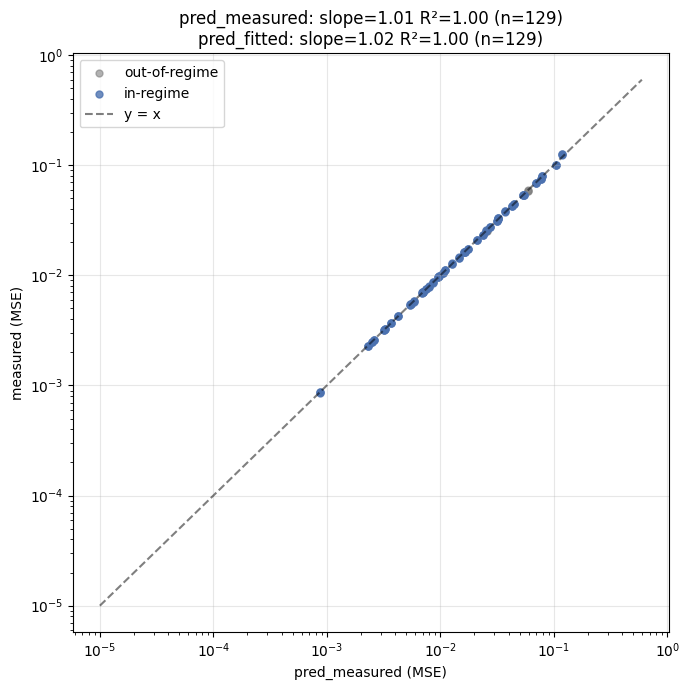

In [50]:
import matplotlib.pyplot as plt


def plot_additivity_scatter(raw_df, fit_results, out_path):
    fig, ax = plt.subplots(figsize=(7, 7))
    in_r = raw_df[raw_df["in_regime"]]
    out_r = raw_df[~raw_df["in_regime"]]
    ax.scatter(out_r["pred_measured_mse"], out_r["mse"], color="grey", alpha=0.6, label="out-of-regime", s=25)
    ax.scatter(in_r["pred_measured_mse"], in_r["mse"], color="#4C72B0", alpha=0.8, label="in-regime", s=25)
    lims = [1e-5, raw_df[["pred_measured_mse", "mse"]].max().max() * 1.2]
    ax.plot(lims, lims, "k--", alpha=0.5, label="y = x")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("pred_measured (MSE)")
    ax.set_ylabel("measured (MSE)")
    pm, pf = fit_results["pred_measured_mse"], fit_results["pred_fitted_mse"]
    ax.set_title(
        f"pred_measured: slope={pm['slope']:.2f} R²={pm['r2']:.2f} (n={pm['n_points']})\n"
        f"pred_fitted: slope={pf['slope']:.2f} R²={pf['r2']:.2f} (n={pf['n_points']})"
    )
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


plot_additivity_scatter(raw_df, FIT_RESULTS, RESULTS_DIR / "additivity_scatter.png")

## 17. Artifact - interaction_bars.png

For the 8 uniform pairs at eps=3e-3: I(i,j) = [D_meas(i,j) - D1(i) -
D1(j)] / [D1(i) + D1(j)] -- how far pairwise measurement deviates from
pure superposition, as a fraction of the additive prediction.

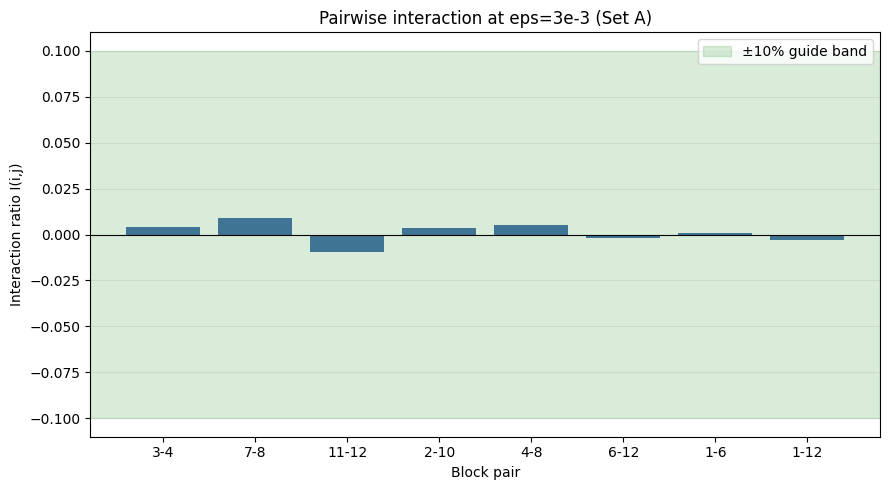

In [51]:
def compute_interaction_ratios(raw_df, pairs, eps, d1_lookup):
    results = []
    for i, j in pairs:
        cid = f"A_p{i}-{j}_e{_fmt_eps(eps)}"
        d_meas = raw_df.loc[raw_df["config_id"] == cid, "mse"].mean()
        d1_i, _ = d1_lookup[(i, round(eps, 10))]
        d1_j, _ = d1_lookup[(j, round(eps, 10))]
        ratio = (d_meas - d1_i - d1_j) / (d1_i + d1_j)
        results.append({"pair": f"{i}-{j}", "interaction_ratio": ratio})
    return pd.DataFrame(results)


def plot_interaction_bars(interaction_df, out_path):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.bar(interaction_df["pair"], interaction_df["interaction_ratio"], color="#4C72B0")
    ax.axhspan(-0.10, 0.10, color="green", alpha=0.15, label="±10% guide band")
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_xlabel("Block pair")
    ax.set_ylabel("Interaction ratio I(i,j)")
    ax.set_title("Pairwise interaction at eps=3e-3 (Set A)")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


INTERACTION_DF = compute_interaction_ratios(raw_df, SET_A_PAIRS, 3e-3, D1_LOOKUP)
plot_interaction_bars(INTERACTION_DF, RESULTS_DIR / "interaction_bars.png")

## 18. Artifact - curvature_plot.png

Ratio D_meas / pred_fitted vs total injected relative energy: shows where
the first-order (fitted) model starts to bend as total energy grows.

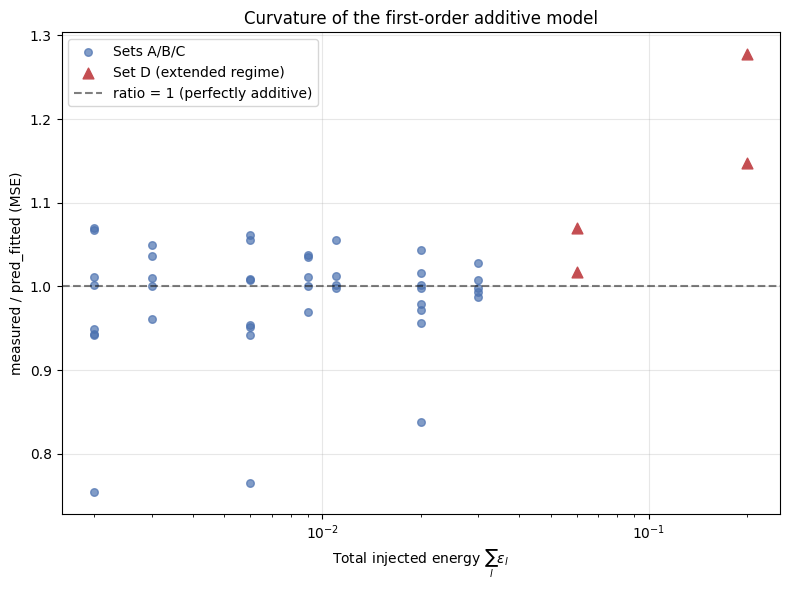

In [52]:
def plot_curvature(raw_df, out_path):
    fig, ax = plt.subplots(figsize=(8, 6))
    agg = raw_df.groupby(["config_id", "family", "total_eps"], as_index=False)[
        ["mse", "pred_fitted_mse"]
    ].mean()
    agg["ratio"] = agg["mse"] / agg["pred_fitted_mse"]
    not_d = agg[agg["family"] != "D"]
    is_d = agg[agg["family"] == "D"]
    ax.scatter(not_d["total_eps"], not_d["ratio"], color="#4C72B0", alpha=0.7, label="Sets A/B/C", s=30)
    ax.scatter(is_d["total_eps"], is_d["ratio"], color="#C44E52", marker="^", s=60, label="Set D (extended regime)")
    ax.axhline(1.0, color="k", linestyle="--", alpha=0.5, label="ratio = 1 (perfectly additive)")
    ax.set_xscale("log")
    ax.set_xlabel(r"Total injected energy $\sum_l \epsilon_l$")
    ax.set_ylabel("measured / pred_fitted (MSE)")
    ax.set_title("Curvature of the first-order additive model")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.show()


plot_curvature(raw_df, RESULTS_DIR / "curvature_plot.png")

## 19. Artifact - E2_summary.json

In [53]:
def _min_block_distance(block_eps):
    blocks = list(block_eps.keys())
    if len(blocks) < 2:
        return 0
    return min(abs(a - b) for a, b in itertools.combinations(blocks, 2))


def build_error_table(raw_df):
    df = raw_df.copy()
    df["rel_error"] = (df["mse"] - df["pred_measured_mse"]).abs() / df["mse"]
    per_config = df.groupby(["config_id", "family", "in_regime"], as_index=False)["rel_error"].mean()
    block_eps_by_config = {r["config_id"]: json.loads(r["block_eps_json"]) for _, r in df.iterrows()}
    per_config["total_eps"] = per_config["config_id"].map(
        lambda cid: sum(float(v) for v in block_eps_by_config[cid].values())
    )
    per_config["min_block_distance"] = per_config["config_id"].map(
        lambda cid: _min_block_distance({int(k): v for k, v in block_eps_by_config[cid].items()})
    )
    per_config["has_block_1"] = per_config["config_id"].map(
        lambda cid: 1 in {int(k) for k in block_eps_by_config[cid]}
    )
    return per_config


ERROR_TABLE = build_error_table(raw_df)
WORST_5 = ERROR_TABLE.sort_values("rel_error", ascending=False).head(5)

# Excludes configs whose rel_error is NaN (arm-D's eps=0.1, which has no
# pred_measured to compare against by design) -- np.corrcoef propagates a
# single NaN input to every output, which would otherwise silently make
# all three correlations NaN instead of reflecting the other 45 configs.
_CORR_TABLE = ERROR_TABLE.dropna(subset=["rel_error"])
CORRELATIONS = {
    "n_points": int(len(_CORR_TABLE)),
    "rel_error_vs_total_eps": float(np.corrcoef(_CORR_TABLE["total_eps"], _CORR_TABLE["rel_error"])[0, 1]),
    "rel_error_vs_min_block_distance": float(
        np.corrcoef(_CORR_TABLE["min_block_distance"], _CORR_TABLE["rel_error"])[0, 1]
    ),
    "rel_error_vs_block_1_inclusion": float(
        np.corrcoef(_CORR_TABLE["has_block_1"].astype(float), _CORR_TABLE["rel_error"])[0, 1]
    ),
}

E2_SUMMARY = {
    "config": CONFIG,
    "config_hash": CONFIG_HASH,
    "environment": ENVIRONMENT,
    "data_source": DATA_SOURCE,
    "n_images_used": N_USED,
    "labels_available": LABELS_AVAILABLE,
    "gate_results": GATE_RESULTS,
    "acceptance": {
        "predictor": "pred_measured_mse", "criterion": "slope in [0.85,1.15] and r2 >= 0.9",
        "result": ACCEPTANCE, "passed": ACCEPTANCE_PASS,
    },
    "fit_results": FIT_RESULTS,
    "error_table": ERROR_TABLE.to_dict("records"),
    "worst_5_offenders": WORST_5.to_dict("records"),
    "interaction_stats": {
        "mean": float(INTERACTION_DF["interaction_ratio"].mean()),
        "std": float(INTERACTION_DF["interaction_ratio"].std()),
        "per_pair": INTERACTION_DF.to_dict("records"),
    },
    "correlations": CORRELATIONS,
    "wall_clock_seconds_this_run": SWEEP_WALL_CLOCK_S,
}
with open(RESULTS_DIR / "E2_summary.json", "w") as f:
    json.dump(E2_SUMMARY, f, indent=2)
print(f"Saved {RESULTS_DIR / 'E2_summary.json'}")

Saved results/E2/E2_summary.json


## 20. Final verdict + LAB_LOG.md sentences

In [54]:
print(f"{'=' * 70}\nE2 ADDITIVITY: {'PASS' if ACCEPTANCE_PASS else 'FAIL'}\n{'=' * 70}")
print(
    f"pred_measured vs measured (MSE, in-regime, n={ACCEPTANCE['n_points']}): "
    f"slope={ACCEPTANCE['slope']:.3f}, R²={ACCEPTANCE['r2']:.3f}"
)

sentence_1 = (
    f"E2 additivity {'PASSES' if ACCEPTANCE_PASS else 'FAILS'}: measured-vs-pred_measured "
    f"(MSE, in-regime, n={ACCEPTANCE['n_points']}) through-origin slope="
    f"{ACCEPTANCE['slope']:.2f}, R²={ACCEPTANCE['r2']:.2f}."
)
sentence_2 = (
    f"Pairwise interaction at eps=3e-3 averages {INTERACTION_DF['interaction_ratio'].mean():.1%} "
    f"(std {INTERACTION_DF['interaction_ratio'].std():.1%}) across the 8 uniform pairs, "
    f"{'within' if abs(INTERACTION_DF['interaction_ratio'].mean()) <= 0.10 else 'outside'} the ±10% guide band."
)
sentence_3 = (
    f"Relative error correlates with total injected energy (rho={CORRELATIONS['rel_error_vs_total_eps']:.2f}) "
    f"and block-1 inclusion (rho={CORRELATIONS['rel_error_vs_block_1_inclusion']:.2f}); "
    f"worst offender is {WORST_5.iloc[0]['config_id']} (rel_error={WORST_5.iloc[0]['rel_error']:.1%})."
)

print("\n--- Paste into LAB_LOG.md ---")
for s in (sentence_1, sentence_2, sentence_3):
    print("-", s)

E2 ADDITIVITY: PASS
pred_measured vs measured (MSE, in-regime, n=129): slope=1.007, R²=0.999

--- Paste into LAB_LOG.md ---
- E2 additivity PASSES: measured-vs-pred_measured (MSE, in-regime, n=129) through-origin slope=1.01, R²=1.00.
- Pairwise interaction at eps=3e-3 averages 0.1% (std 0.6%) across the 8 uniform pairs, within the ±10% guide band.
- Relative error correlates with total injected energy (rho=nan) and block-1 inclusion (rho=nan); worst offender is D_p7-8_e3e-2 (rel_error=6.1%).


## Save your results (optional -- Colab sessions are ephemeral)

`results/E2/` only exists in THIS Colab VM's disk. Push it back to your
repo so it persists and so E3-E5 can find it on a fresh clone. Not run
automatically -- uncomment and run only if you want to push.

In [ ]:
# get_ipython().system(
#     'git add results/ && '
#     'git commit -m "E2 results" && '
#     'git push'
# )